# TP 8
---

### Exrcice 2 :

In [1]:
import numpy as np
import pandas as pd

In [8]:
# Tableau de contingence
data = np.array([
    [20, 15, 25, 10],  # Jeune
    [10, 25, 15, 20],  # Adulte
    [5,  10, 20, 10]   # Senior
])

clients = ["Jeune", "Adulte", "Senior"]
produits = ["Produit A", "Produit B", "Produit C", "Produit D"]

df = pd.DataFrame(data, index=clients, columns=produits)
df


,Produit A,Produit B,Produit C,Produit D
Jeune,20,15,25,10
Adulte,10,25,15,20
Senior,5,10,20,10


In [9]:
# Totaux par ligne
totaux_lignes = df.sum(axis=1)

# Totaux par colonne
totaux_colonnes = df.sum(axis=0)

# Total général
total_general = df.values.sum()

print("Totaux par ligne :\n", totaux_lignes)
print("\nTotaux par colonne :\n", totaux_colonnes)
print("\nTotal général :", total_general)


Totaux par ligne :
 Jeune     70
Adulte    70
Senior    45
dtype: int64

Totaux par colonne :
 Produit A    35
Produit B    50
Produit C    60
Produit D    40
dtype: int64

Total général : 185


In [10]:
# Proportions des colonnes p·j
p_j = totaux_colonnes / total_general

# Profils lignes
profils = df.div(totaux_lignes, axis=0)

# Fonction distance du khi-deux
def distance_khi2(i, k):
    return np.sum(((profils.iloc[i] - profils.iloc[k]) ** 2) / p_j)

# Calcul des distances
distances = pd.DataFrame(
    np.zeros((3, 3)),
    index=clients,
    columns=clients
)

for i in range(3):
    for k in range(3):
        distances.iloc[i, k] = distance_khi2(i, k)

distances


,Jeune,Adulte,Senior
Jeune,0.000000,0.340695,0.214007
Adulte,0.340695,0.000000,0.254658
Senior,0.214007,0.254658,0.000000


### Exercice 3 :

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [6]:
# Tableau de contingence
data = np.array([
    [30, 20, 10,  5, 15],  # 18-25
    [25, 30, 20, 10, 15],  # 26-35
    [10, 20, 25, 15, 10],  # 36-50
    [ 5, 10, 20, 25,  5]   # 51+
])

ages = ["18-25", "26-35", "36-50", "51+"]
genres = ["Action", "Comédie", "Drame", "Documentaire", "Science-fiction"]

df = pd.DataFrame(data, index=ages, columns=genres)
df


,Action,Comédie,Drame,Documentaire,Science-fiction
18-25,30,20,10,5,15
26-35,25,30,20,10,15
36-50,10,20,25,15,10
51+,5,10,20,25,5


In [7]:
tot_lignes = df.sum(axis=1)
tot_colonnes = df.sum(axis=0)
total = df.values.sum()

print("Totaux lignes:\n", tot_lignes)
print("\nTotaux colonnes:\n", tot_colonnes)
print("\nTotal général:", total)


Totaux lignes:
 18-25     80
26-35    100
36-50     80
51+       65
dtype: int64

Totaux colonnes:
 Action             70
Comédie            80
Drame              75
Documentaire       55
Science-fiction    45
dtype: int64

Total général: 325


In [13]:
profils_lignes = df.div(tot_lignes, axis=0)
profils_lignes


,Produit A,Produit B,Produit C,Produit D
18-25,NaN,NaN,NaN,NaN
26-35,NaN,NaN,NaN,NaN
36-50,NaN,NaN,NaN,NaN
51+,NaN,NaN,NaN,NaN
Adulte,NaN,NaN,NaN,NaN
Jeune,NaN,NaN,NaN,NaN
Senior,NaN,NaN,NaN,NaN


In [14]:
p_j = tot_colonnes / total
p_j


Action             0.215385
Comédie            0.246154
Drame              0.230769
Documentaire       0.169231
Science-fiction    0.138462
dtype: float64

In [15]:
def distance_khi2(i, k):
    return np.sum(((profils_lignes.iloc[i] - profils_lignes.iloc[k])**2) / p_j)

distances = pd.DataFrame(
    np.zeros((4,4)),
    index=ages,
    columns=ages
)

for i in range(4):
    for k in range(4):
        distances.iloc[i, k] = distance_khi2(i, k)

distances


,18-25,26-35,36-50,51+
18-25,0.0,0.0,0.0,0.0
26-35,0.0,0.0,0.0,0.0
36-50,0.0,0.0,0.0,0.0
51+,0.0,0.0,0.0,0.0


In [18]:
F = df / total

r = F.sum(axis=1).values
c = F.sum(axis=0).values

Dr_inv_sqrt = np.diag(1 / np.sqrt(r))
Dc_inv_sqrt = np.diag(1 / np.sqrt(c))

S = Dr_inv_sqrt @ (F.values - np.outer(r, c)) @ Dc_inv_sqrt

U, singular_values, VT = np.linalg.svd(S, full_matrices=False)

print("Valeurs singulières :", singular_values)



Valeurs singulières : [0.43076923 0.25463826 0.16453473]


IndexError: index 3 is out of bounds for axis 0 with size 3

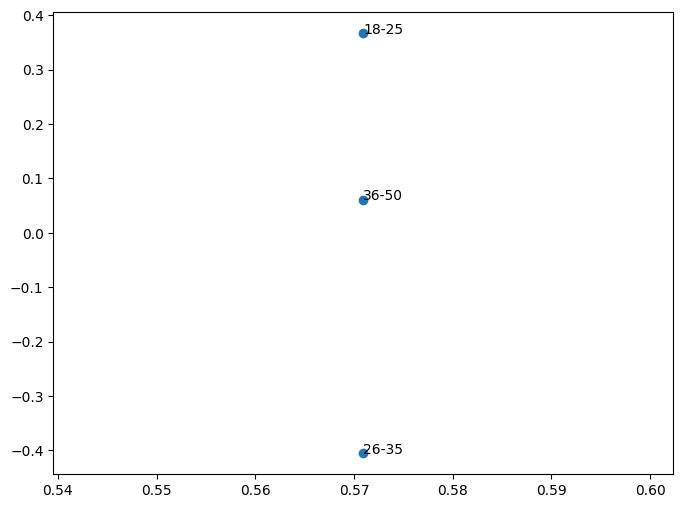

In [21]:
Sigma = np.diag(singular_values)

coord_lignes = Dr_inv_sqrt @ U @ Sigma
coord_colonnes = Dc_inv_sqrt @ VT.T @ Sigma

plt.figure(figsize=(8,6))

# Lignes
plt.scatter(coord_lignes[:,0], coord_lignes[:,1])
for i, label in enumerate(ages):
    plt.text(coord_lignes[i,0], coord_lignes[i,1], label)

# Colonnes
plt.scatter(coord_colonnes[:,0], coord_colonnes[:,1], marker='x')
for j, label in enumerate(genres):
    plt.text(coord_colonnes[j,0], coord_colonnes[j,1], label)

plt.axhline(0)
plt.axvline(0)
plt.xlabel("Axe 1")
plt.ylabel("Axe 2")
plt.title("Plan factoriel AFC (Axe 1 x Axe 2)")
plt.grid()
plt.show()
